In [1]:
!nvidia-smi

Wed May 28 06:10:18 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 570.133.20             Driver Version: 570.133.20     CUDA Version: 12.8     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   30C    P0             41W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

**NOTE:** To make it easier for us to manage datasets, images and models we create a `HOME` constant.

In [2]:
import os
HOME = os.getcwd()
print(HOME)

/content


## Install YOLO11 via Ultralytics

In [3]:
%pip install "ultralytics<=8.3.40" supervision roboflow
import ultralytics
ultralytics.checks()

Ultralytics 8.3.40 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)
Setup complete ✅ (12 CPUs, 83.5 GB RAM, 42.1/94.3 GB disk)


## Fine-tune YOLO11 on custom dataset

**NOTE:** When training YOLOv11, make sure your data is located in `datasets`. If you'd like to change the default location of the data you want to use for fine-tuning, you can do so through Ultralytics' `settings.json`. In this tutorial, we will use one of the [datasets](https://universe.roboflow.com/ks-fsm9o/pelvis-ap-x-ray) available on [Roboflow Universe](https://universe.roboflow.com/). When downloading, make sure to select the `yolov11` export format.

In [4]:
!mkdir {HOME}/datasets
%cd {HOME}/datasets

!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="YKjKJq9jwCbXAUxun5s3")
project = rf.workspace("work-4u6cx").project("i-segmentation-akjbc")
version = project.version(3)
dataset = version.download("yolov11")


/content/datasets
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to I-Segmentation--3 in yolov11:: 100%|██████████| 6894/6894 [00:01<00:00, 6161.10it/s]


## Custom Training

In [5]:
%cd {HOME}

!yolo task=detect mode=train model=yolo11s-seg.pt data={dataset.location}/data.yaml epochs=300 imgsz=640 plots=True

/content
100% 19.7M/19.7M [00:00<00:00, 149MB/s]
WARNING ⚠️ conflicting 'task=detect' passed with 'task=segment' model. Ignoring 'task=detect' and updating to 'task=segment' to match model.
New https://pypi.org/project/ultralytics/8.3.146 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.40 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)
engine/trainer: task=segment, mode=train, model=yolo11s-seg.pt, data=/content/datasets/I-Segmentation--3/data.yaml, epochs=300, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None

**NOTE:** The results of the completed training are saved in `{HOME}/runs/detect/train/`. Let's examine them.

In [6]:
!ls {HOME}/runs/segment/train/

args.yaml					   MaskF1_curve.png	 train_batch54521.jpg
BoxF1_curve.png					   MaskP_curve.png	 train_batch54522.jpg
BoxP_curve.png					   MaskPR_curve.png	 val_batch0_labels.jpg
BoxPR_curve.png					   MaskR_curve.png	 val_batch0_pred.jpg
BoxR_curve.png					   results.csv		 val_batch1_labels.jpg
confusion_matrix_normalized.png			   results.png		 val_batch1_pred.jpg
confusion_matrix.png				   train_batch0.jpg	 val_batch2_labels.jpg
events.out.tfevents.1748412656.b0d19e510608.375.0  train_batch1.jpg	 val_batch2_pred.jpg
labels_correlogram.jpg				   train_batch2.jpg	 weights
labels.jpg					   train_batch54520.jpg


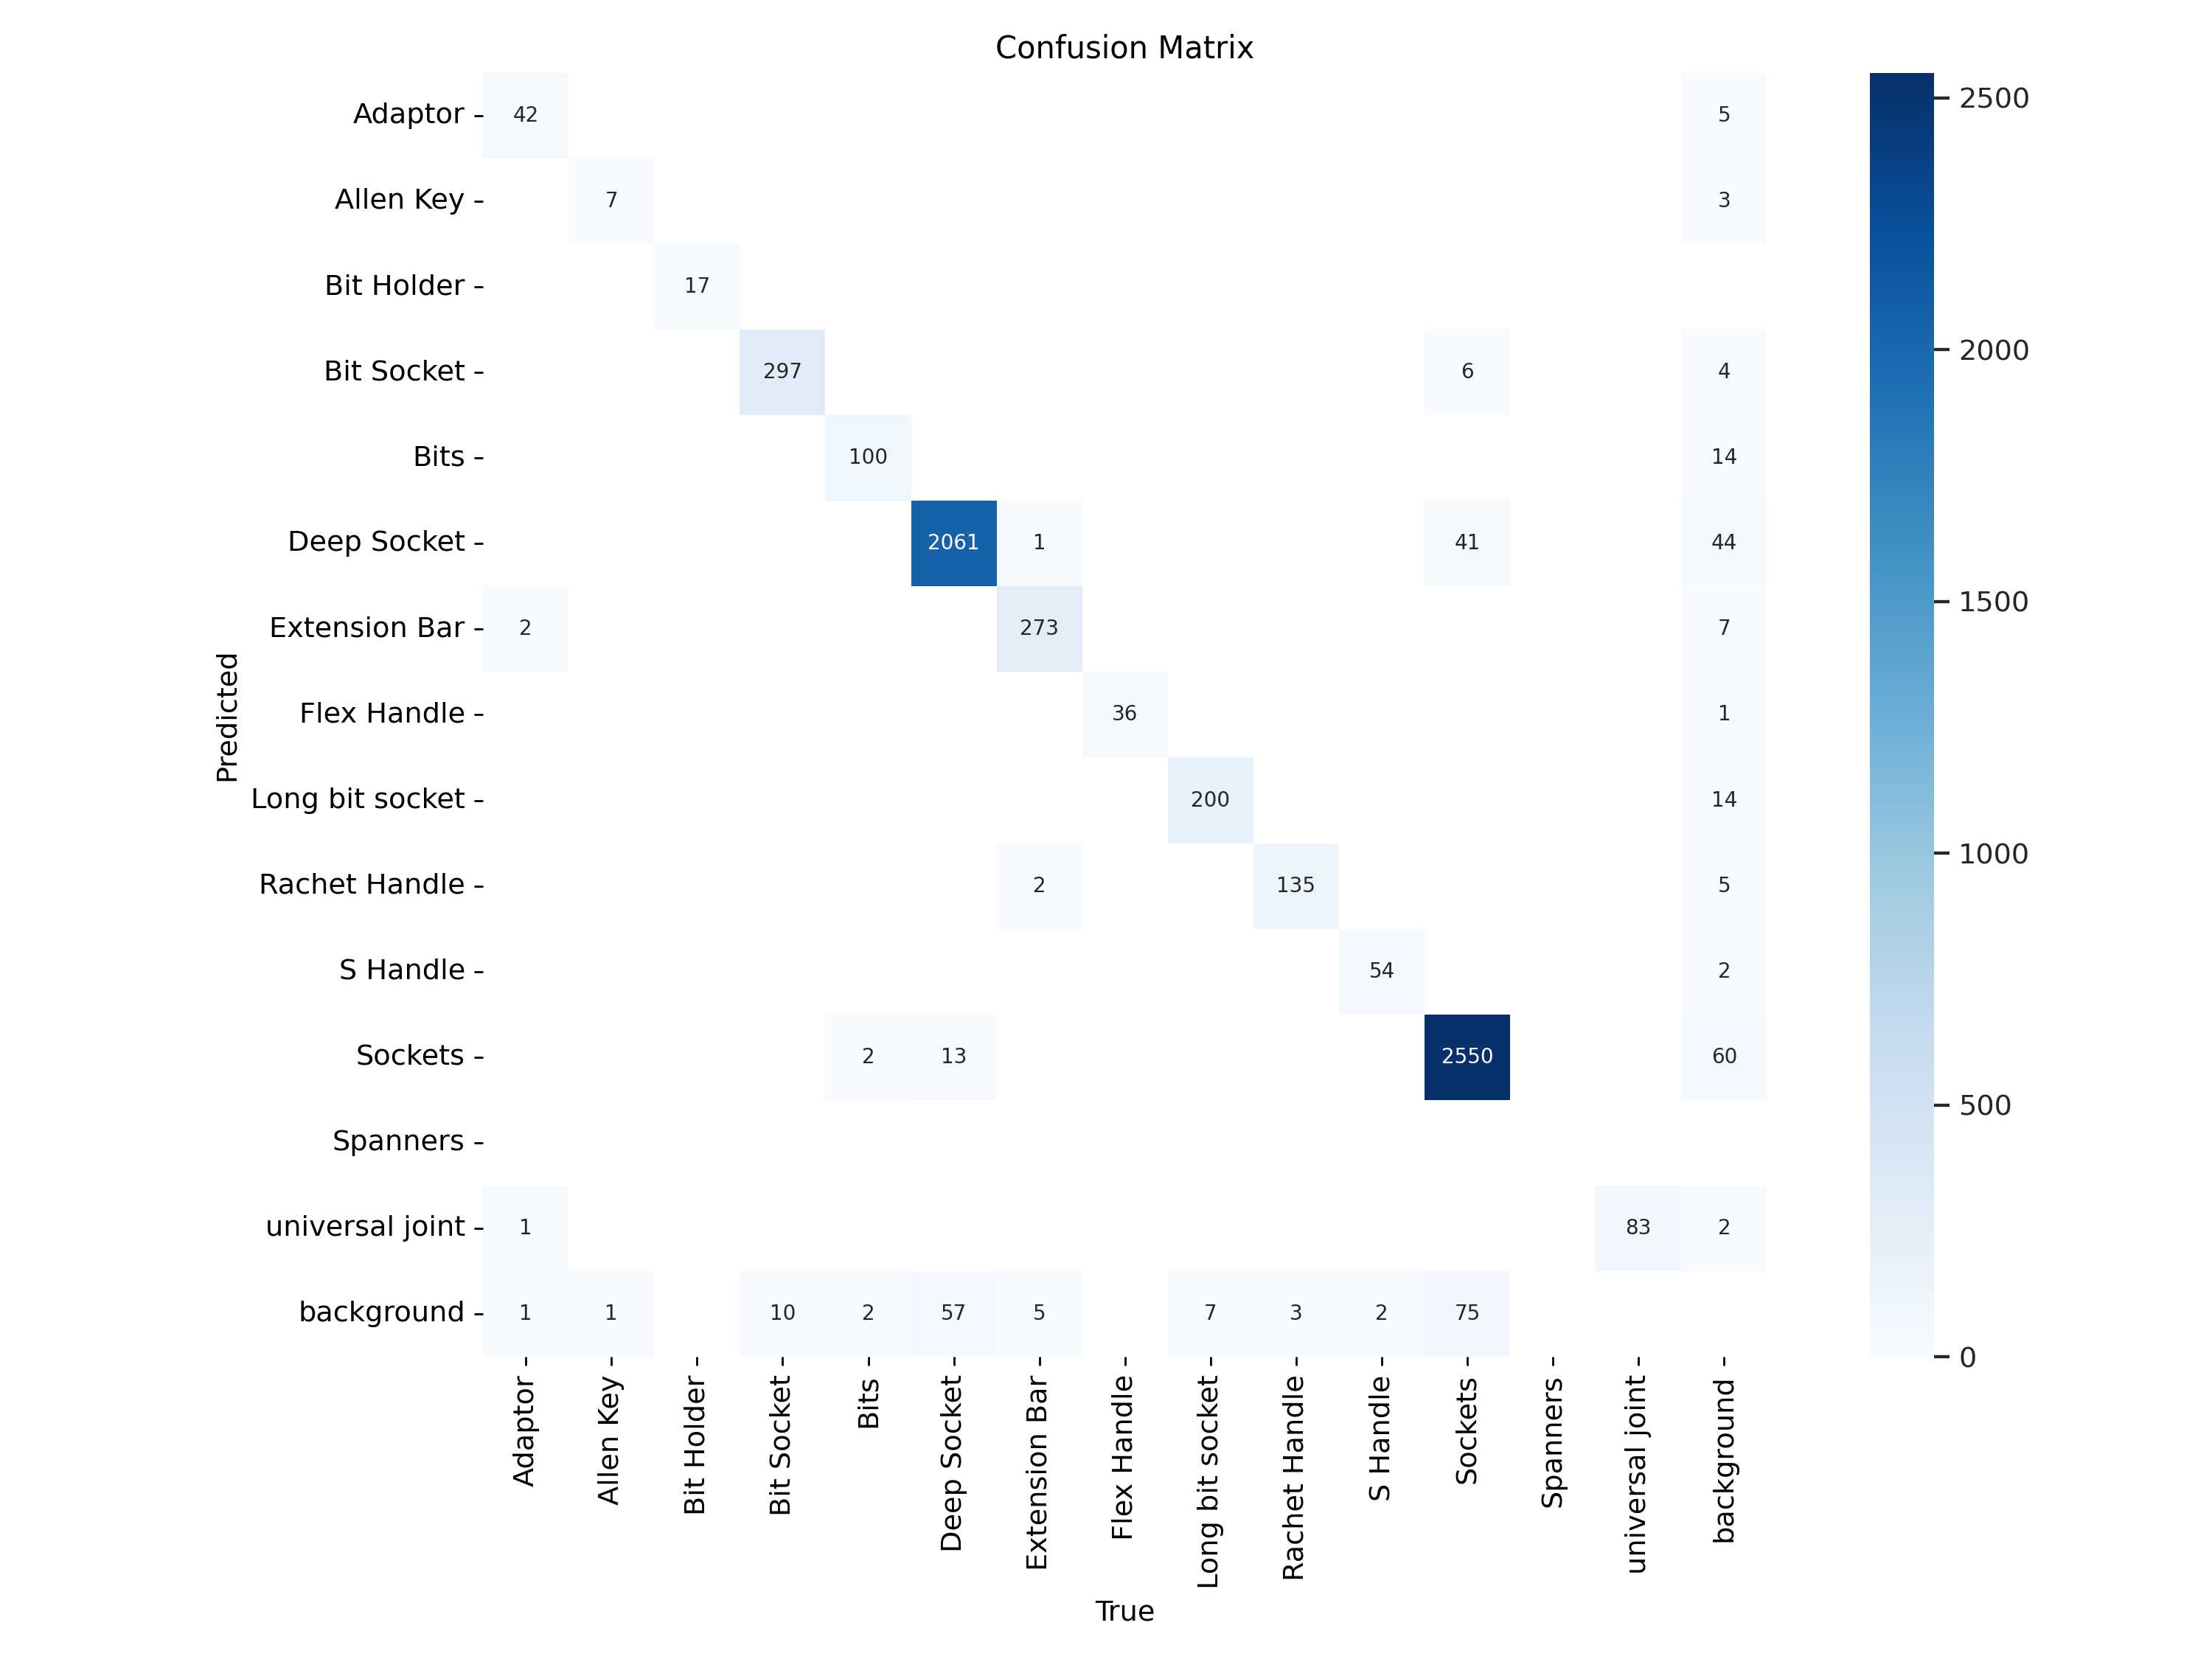

In [7]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/segment/train/confusion_matrix.png', width=600)

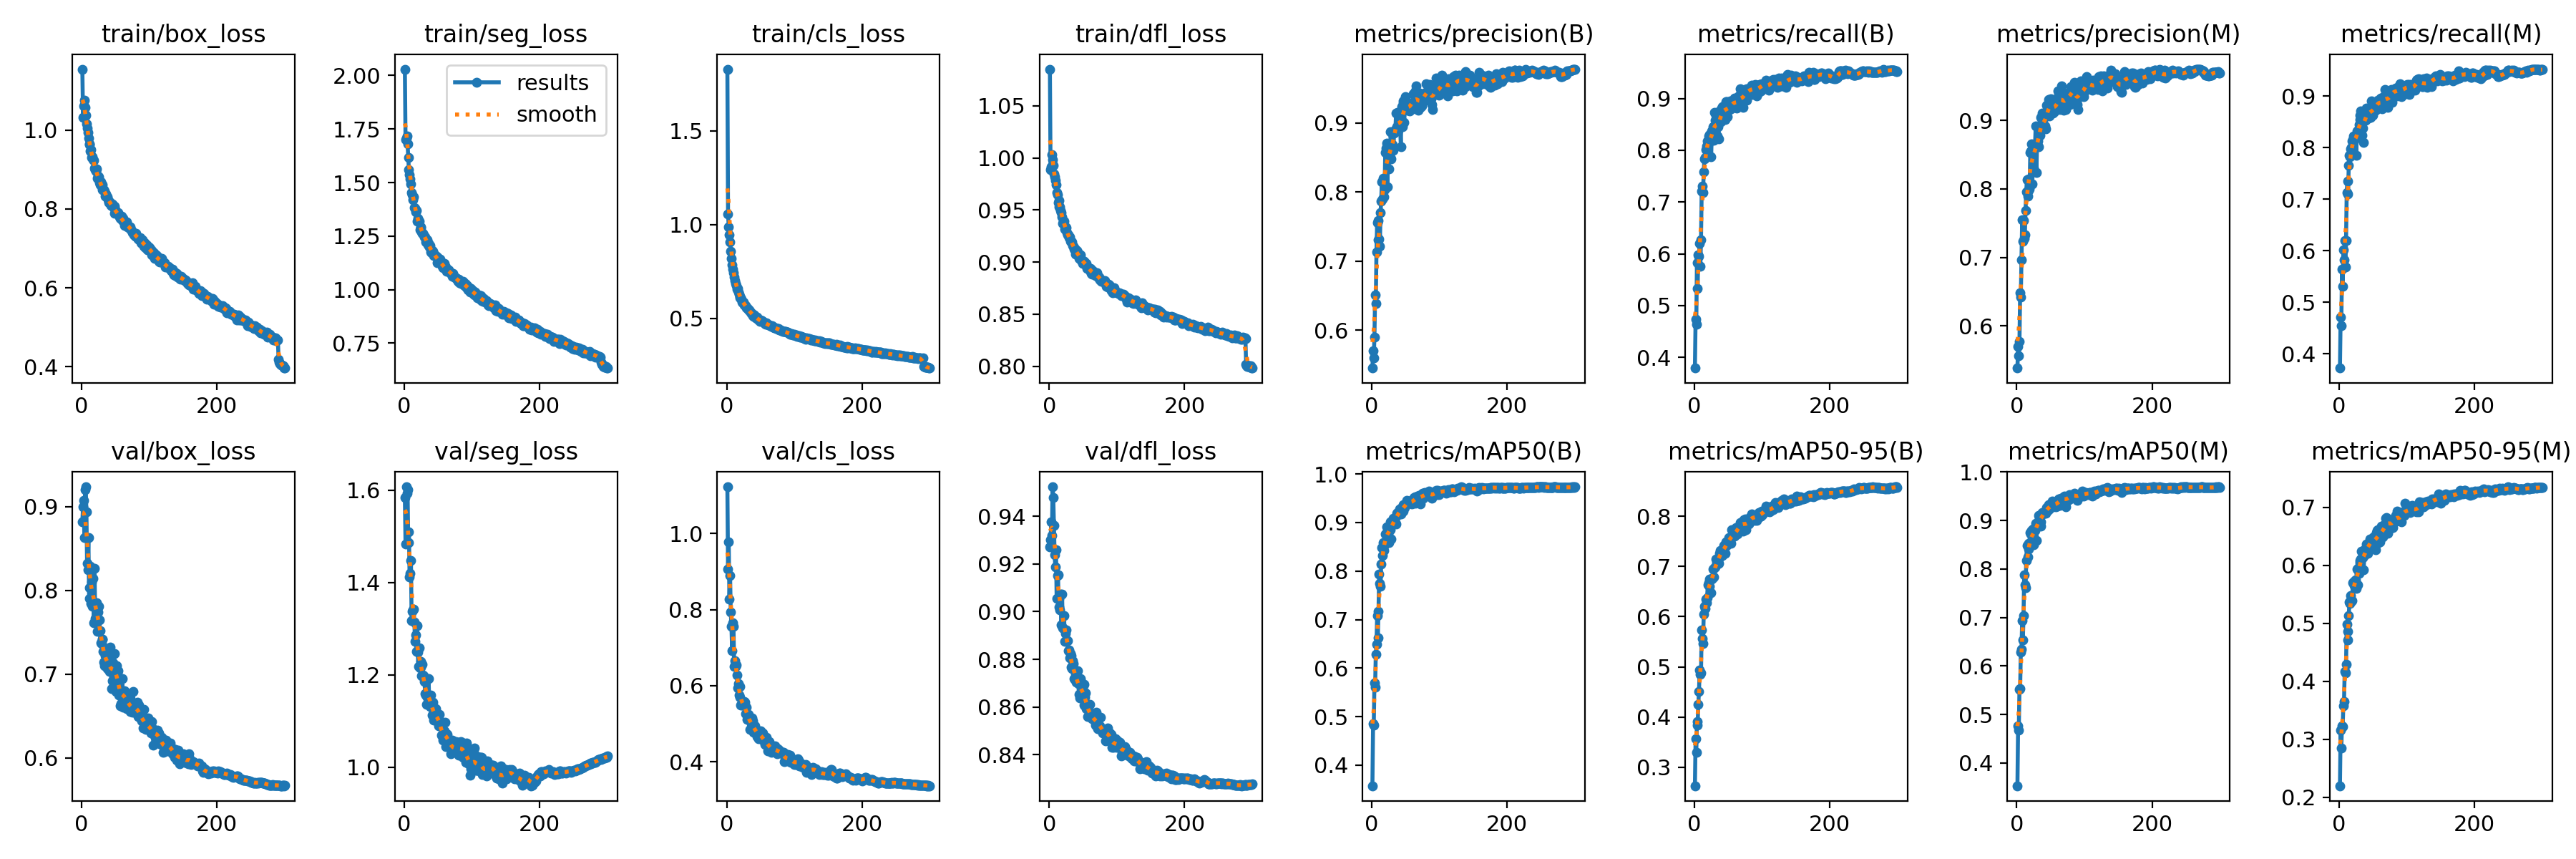

In [8]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/segment/train/results.png', width=600)

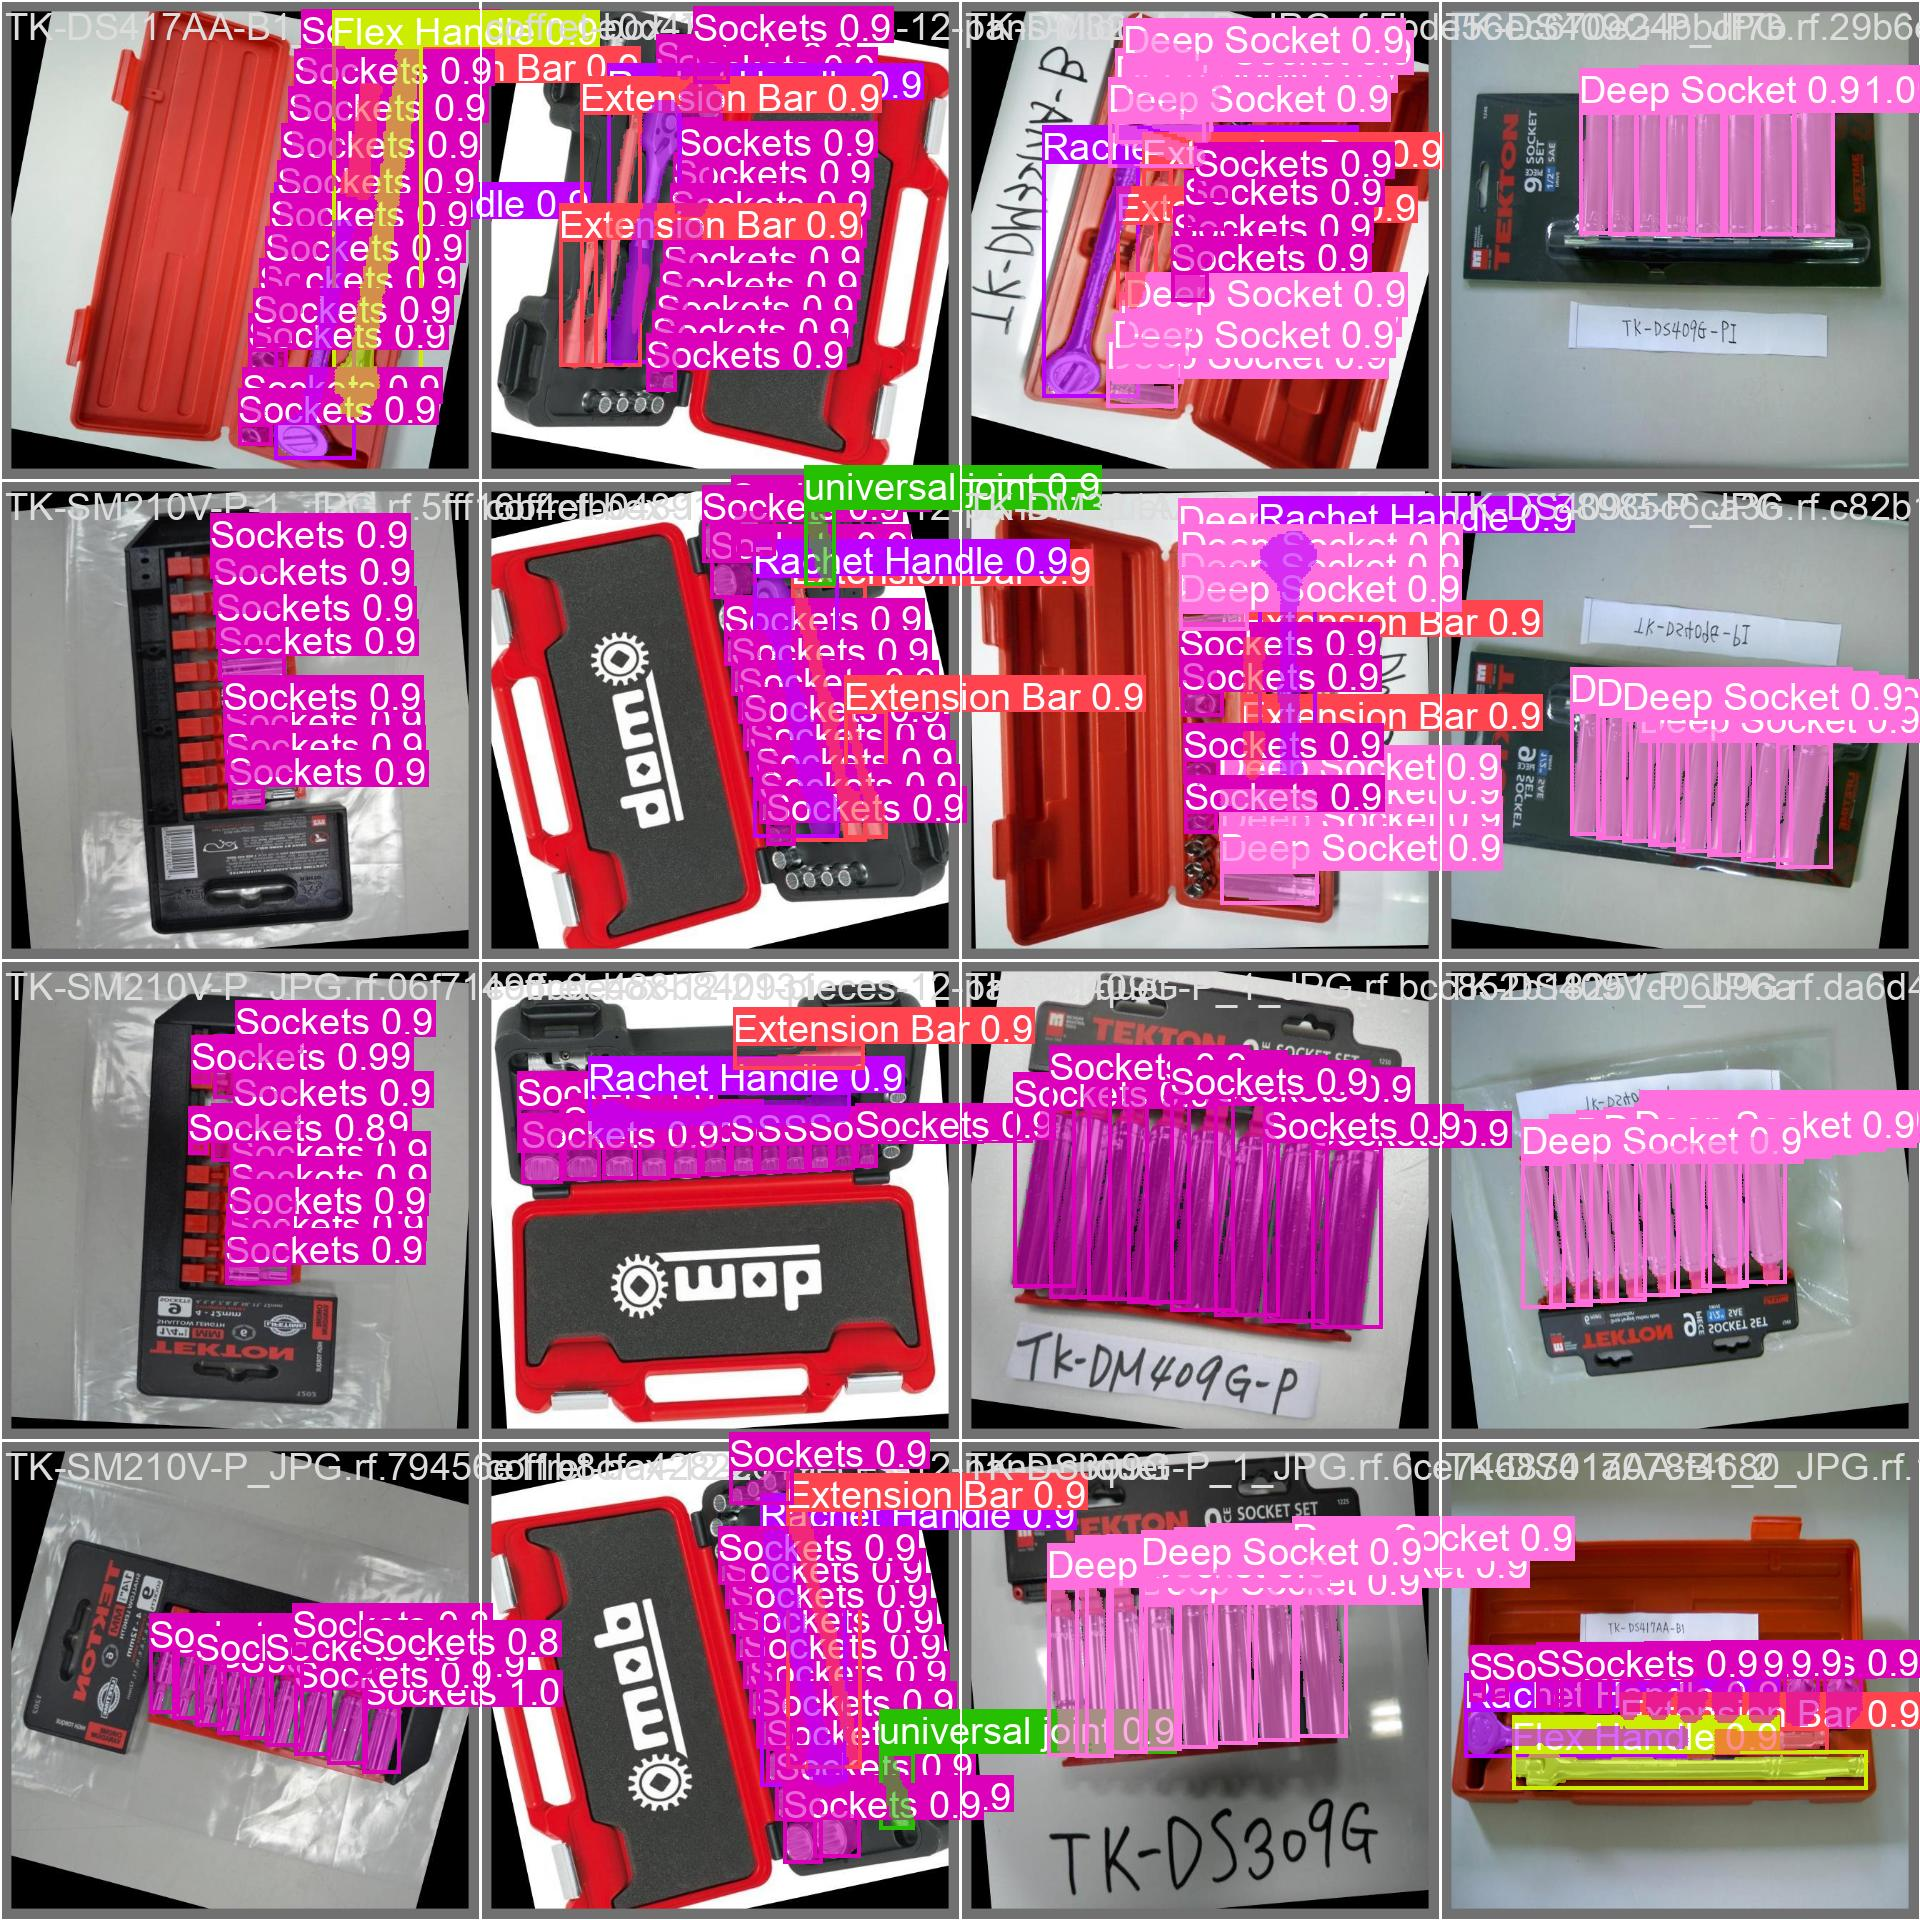

In [9]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/segment/train/val_batch0_pred.jpg', width=600)

## Validate fine-tuned model

In [10]:
!yolo task=detect mode=val model={HOME}/runs/segment/train/weights/best.pt data={dataset.location}/data.yaml

WARNING ⚠️ conflicting 'task=detect' passed with 'task=segment' model. Ignoring 'task=detect' and updating to 'task=segment' to match model.
Ultralytics 8.3.40 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)
YOLO11s-seg summary (fused): 265 layers, 10,072,234 parameters, 0 gradients, 35.3 GFLOPs
val: Scanning /content/datasets/I-Segmentation--3/valid/labels.cache... 287 images, 0 backgrounds, 0 corrupt: 100% 287/287 [00:00<?, ?it/s]
val: WARNING ⚠️ /content/datasets/I-Segmentation--3/valid/images/96522_png.rf.054e6cde714bf1f89a760cacb7085cc7.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% 18/18 [00:06<00:00,  2.76it/s]
                   all        287       6086      0.978      0.954      0.973      0.857       0.97      0.951      0.967      0.727
               Adaptor         33         46      0.975      0.865      0.951      0.797 

## Inference with custom model

In [11]:
!yolo task=detect mode=predict model={HOME}/runs/segment/train/weights/best.pt conf=0.25 source={dataset.location}/test/images save=True

WARNING ⚠️ conflicting 'task=detect' passed with 'task=segment' model. Ignoring 'task=detect' and updating to 'task=segment' to match model.
Ultralytics 8.3.40 🚀 Python-3.10.12 torch-2.5.1+cu121 CUDA:0 (NVIDIA A100-SXM4-40GB, 40442MiB)
YOLO11s-seg summary (fused): 265 layers, 10,072,234 parameters, 0 gradients, 35.3 GFLOPs

image 1/146 /content/datasets/I-Segmentation--3/test/images/20240703_140727_jpg.rf.b97294895d6c696f5bc54fc1f8c6f9a5.jpg: 640x640 3 Adaptors, 1 Bit Holder, 21 Bit Sockets, 13 Deep Sockets, 3 Extension Bars, 1 Rachet Handle, 1 S Handle, 27 Socketss, 3 universal joints, 13.5ms
image 2/146 /content/datasets/I-Segmentation--3/test/images/20240703_141501_jpg.rf.6a694cef9f2e71cf1f69c292c14c2ee4.jpg: 640x640 41 Deep Sockets, 3 Extension Bars, 34 Socketss, 1 universal joint, 11.9ms
image 3/146 /content/datasets/I-Segmentation--3/test/images/22_webp.rf.420285e59bc04a60d179f03e201c12de.jpg: 640x640 1 Allen Key, 1 Bit Holder, 1 Bits, 1 Extension Bar, 1 Rachet Handle, 3 S Handle

**NOTE:** Let's take a look at few results.

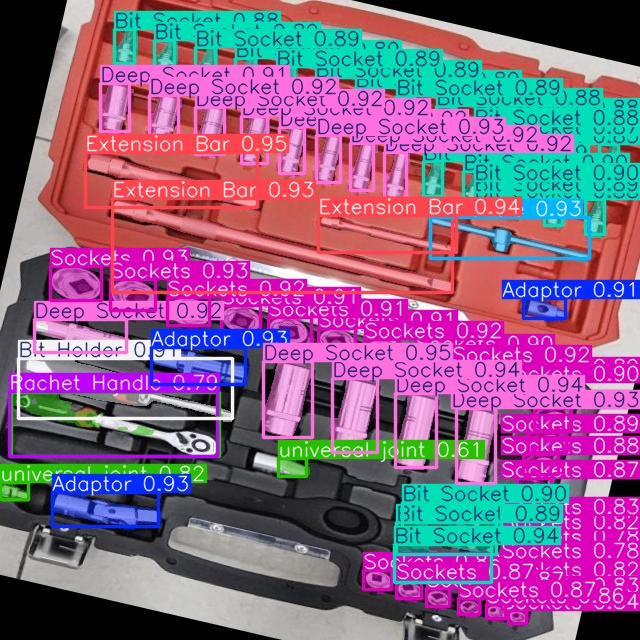

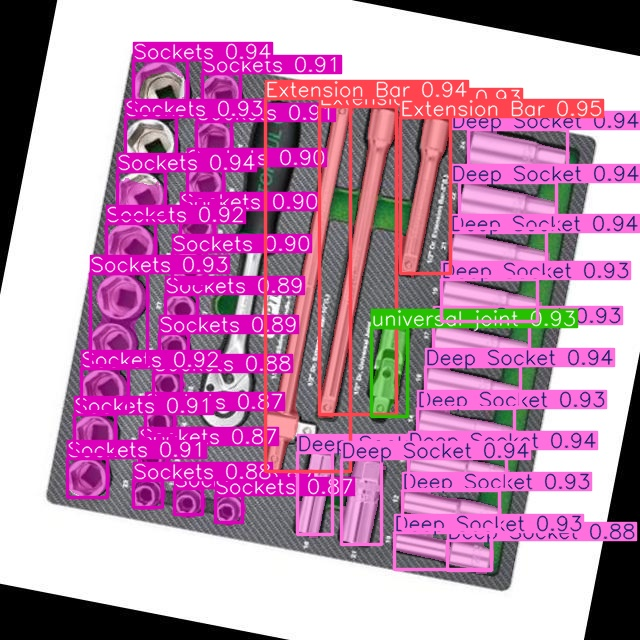

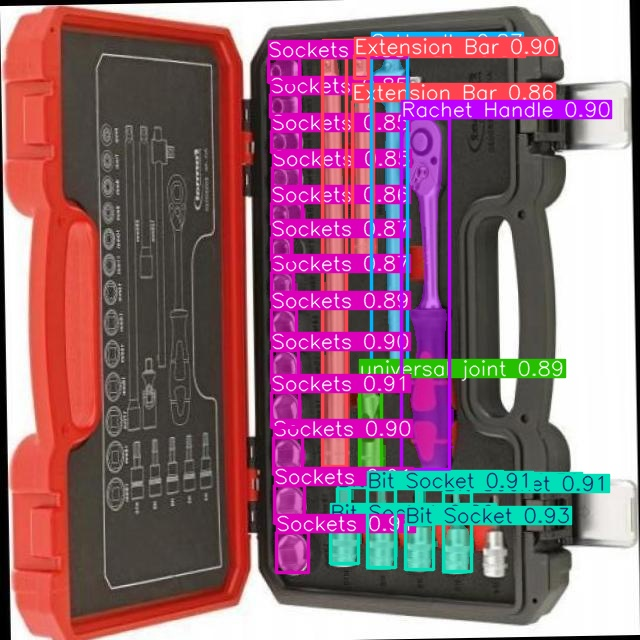

In [12]:
import glob
import os
from IPython.display import Image as IPyImage, display

latest_folder = max(glob.glob(f'{HOME}/runs/segment/predict*/'), key=os.path.getmtime)
for img in glob.glob(f'{latest_folder}/*.jpg')[:3]:
    display(IPyImage(filename=img, width=600))
    print("\n")